# Question 7 — Combien de types de séjours Valmont a-t-il vraiment ?

**Auteur : Wenceslas Bouity** — Projet Valmont, Datamining B3 (ECE Paris), sujet 9.

La direction raisonne aujourd'hui avec trois segments déclarés à la réservation : affaires, loisir, groupe.
Cette question demande si ces trois étiquettes correspondent vraiment à la façon dont les clients se comportent,
ou si les données en révèlent d'autres. La réponse sert de socle à la question 8, qui construit une politique
commerciale par type.

**Méthode** : classification non supervisée (K-means et classification hiérarchique de Ward) sur les variables
qui décrivent le séjour, sans utiliser le segment déclaré. Le nombre de groupes est choisi sur des critères
chiffrés : coude, silhouette, Calinski-Harabasz, Davies-Bouldin, et stabilité par rééchantillonnage.

**Point de départ** : `data/clean/valmont_clean.csv`, le fichier propre commun produit par le notebook 00.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             calinski_harabasz_score, davies_bouldin_score)
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency, kruskal

# Graine fixe : K-means part de centres tires au hasard, deux executions sans graine
# ne donnent pas exactement les memes groupes. random_state=42 rend le notebook reproductible.
GRAINE = 42

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Charte graphique du notebook : 4 teintes fixes, une par type de sejour, verifiees
# pour rester distinguables en vision des couleurs deficiente.
COULEURS = ["#257de0", "#00b894", "#f2a600", "#ec4647"]
ENCRE, ENCRE_2, GRILLE = "#191919", "#666666", "#dcdcdc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlecolor": ENCRE, "axes.grid": True,
    "grid.color": GRILLE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

reservations = pd.read_csv("../data/clean/valmont_clean.csv")
print("Fichier propre commun :", reservations.shape[0], "réservations,", reservations.shape[1], "colonnes")

# motif_anomalie est vide pour les reservations normales : c'est voulu, ce n'est pas une donnee manquante.
# Je controle donc l'absence de trous sur toutes les autres colonnes.
trous = reservations.drop(columns=["motif_anomalie"]).isna().sum()
print("Valeurs manquantes hors colonne de motif :", int(trous.sum()))
print("Réservations portant un motif d'anomalie :", int(reservations["motif_anomalie"].notna().sum()))

Fichier propre commun : 800 réservations, 23 colonnes
Valeurs manquantes hors colonne de motif : 0
Réservations portant un motif d'anomalie : 6


## 1. Périmètre retenu

Le notebook 00 a marqué 6 réservations impossibles (séjours de 365 nuits, prix de nuit à 0 €) avec la colonne
`flag_anomalie`. La décision d'équipe est de les exclure des modèles et de les traiter en question 9.

Je les exclus ici pour une raison précise : K-means minimise une somme de carrés d'écarts, il est donc très
sensible aux valeurs extrêmes. Un séjour de 365 nuits tirerait à lui seul un centre de classe et créerait un
groupe d'une seule réservation. Je vérifie plus bas que ces 6 lignes sont bien les seules écartées.

In [2]:
sejours = reservations[reservations["flag_anomalie"] == 0].copy().reset_index(drop=True)

print("Réservations analysées :", len(sejours), f"({len(reservations) - len(sejours)} anomalies écartées)")
print("\nMotifs des lignes écartées :")
print(reservations.loc[reservations["flag_anomalie"] == 1, "motif_anomalie"].value_counts().to_string())

# Apres exclusion, les valeurs extremes redeviennent plausibles pour un hotel
print("\nÉtendue des variables de séjour après exclusion :")
print(sejours[["nb_nuits", "nb_personnes", "delai_reservation_j", "prix_nuit_eur"]]
      .agg(["min", "median", "max"]).round(1).to_string())

Réservations analysées : 794 (6 anomalies écartées)

Motifs des lignes écartées :
motif_anomalie
prix_nul            3
sejour_365_nuits    3

Étendue des variables de séjour après exclusion :
        nb_nuits  nb_personnes  delai_reservation_j  prix_nuit_eur
min          1.0           1.0                  0.0           46.6
median       3.0           1.0                 28.0          153.0
max          9.0          18.0                235.0          481.1


## 2. Quelles variables décrivent un « type de séjour » ?

C'est la décision qui porte toute la question : K-means ne fait que regrouper des points dans l'espace qu'on lui
donne. Changer les variables change la typologie. Je pars donc d'une règle : **ne garder que ce qui décrit le
séjour au moment où il est réservé.**

| Variable | Retenue ? | Pourquoi |
| --- | --- | --- |
| `nb_nuits`, `nb_personnes`, `delai_reservation_j` | **oui** | Ce sont les trois seules variables continues qui décrivent le séjour lui-même : sa durée, sa taille, son horizon de réservation. |
| `segment_declare` | non | C'est précisément l'étiquette que la question met en doute. L'utiliser reviendrait à retrouver les trois segments par construction. Elle sert de comparaison, à la fin. |
| `a_annule` | non | C'est un résultat, connu seulement après coup. Si je classais dessus, dire ensuite que les types s'annulent différemment serait un raisonnement circulaire. Je la garde comme **variable de validation externe**. |
| `prix_nuit_eur` | non | Vérifié ci-dessous : le prix est porté à 89 % par la catégorie de l'hôtel. Il décrit l'hôtel choisi, pas le comportement du client. |
| `weekend`, `petit_dejeuner` | non | Variables 0/1 : la distance euclidienne de K-means n'a pas de sens sur une variable binaire, elle n'y mesure qu'une égalité. Je vérifie après coup qu'elles ne portent pas de typologie. |
| `canal` | non | Variable qualitative à 4 modalités ; même problème, et le notebook 00 a montré un écart d'annulation faible entre canaux. Vérifiée après coup elle aussi. |
| `ville`, `categorie`, `chambres`, `salles_seminaire`, `distance_gare_km` | non | Décrivent l'hôtel, pas le séjour. |
| `nuitees_cumulees_client` | non | Décrit l'historique du client, pas le séjour en cours. Testée : elle fait chuter la silhouette de 0,44 à 0,27 sans créer de groupe interprétable. |

Les deux vérifications annoncées (prix ≈ catégorie, et absence de lien entre les variables écartées et les
types) sont faites : la première tout de suite, la seconde en partie 6, une fois les types construits.

In [3]:
# Le prix de la nuit decrit-il le sejour ou l'hotel ?
# Rapport de correlation eta^2 : part de la variance du prix expliquee par la categorie de l'hotel.
moyennes = sejours.groupby("categorie")["prix_nuit_eur"].agg(["mean", "size"])
moyenne_generale = sejours["prix_nuit_eur"].mean()
var_inter = ((moyennes["mean"] - moyenne_generale) ** 2 * moyennes["size"]).sum()
var_totale = ((sejours["prix_nuit_eur"] - moyenne_generale) ** 2).sum()
eta2 = var_inter / var_totale

print(f"Variance du prix expliquée par la catégorie de l'hôtel : eta² = {eta2:.3f}")
print(sejours.groupby("categorie")["prix_nuit_eur"].agg(["size", "mean", "std"]).round(1).to_string())
print("\nLe prix est donc d'abord une caractéristique de l'hôtel : il reste dehors et servira à décrire les types (Q8).")

# Les trois variables retenues sont-elles redondantes entre elles ?
VARIABLES = ["nb_nuits", "nb_personnes", "delai_reservation_j"]
print("\nCorrélations de Spearman entre les trois variables retenues :")
print(sejours[VARIABLES].corr(method="spearman").round(2).to_string())

Variance du prix expliquée par la catégorie de l'hôtel : eta² = 0.887
           size   mean   std
categorie                   
3 étoiles   306  109.1  23.7
4 étoiles   265  165.9  27.9
5 étoiles   223  349.4  52.6

Le prix est donc d'abord une caractéristique de l'hôtel : il reste dehors et servira à décrire les types (Q8).

Corrélations de Spearman entre les trois variables retenues :
                     nb_nuits  nb_personnes  delai_reservation_j
nb_nuits                 1.00          0.02                 0.18
nb_personnes             0.02          1.00                 0.55
delai_reservation_j      0.18          0.55                 1.00


**Lecture** : eta² = 0,887. Près de 89 % de la variation du prix de la nuit vient du nombre d'étoiles
(109 € en 3 étoiles, 166 € en 4, 349 € en 5). Le mettre dans la classification reviendrait à regrouper les
réservations par catégorie d'hôtel, pas par type de séjour.

Les trois variables retenues ne sont pas redondantes : la plus forte corrélation est de 0,55 entre le nombre de
personnes et le délai (les groupes s'organisent longtemps à l'avance), les deux autres sont sous 0,20. Chacune
apporte donc une information propre.

## 3. Préparation : pourquoi standardiser

Les trois variables n'ont ni la même unité ni la même étendue : 1 à 9 nuits, 1 à 18 personnes, 0 à 235 jours.
K-means additionne des carrés d'écarts, donc sans mise à l'échelle le délai écraserait tout : un écart de
50 jours pèserait 50² = 2 500 quand un écart de 3 nuits ne pèse que 9. La typologie ne serait qu'un découpage
du délai.

Je centre et réduis chaque variable (`StandardScaler`) : chacune a ensuite une moyenne de 0 et un écart-type
de 1, et les trois pèsent le même poids. **C'est un choix, pas une neutralité** : il revient à dire qu'un écart
d'un écart-type a la même importance sur les trois variables.

J'ai aussi testé une transformation logarithmique avant standardisation, pour corriger l'asymétrie des
distributions (coefficient d'asymétrie de 1,8 sur le nombre de personnes). Je la compare en partie 5 et je ne
la retiens pas : le logarithme écrase précisément l'écart qui intéresse l'hôtel, entre une réservation de
2 personnes et un groupe de 14.

In [4]:
X = sejours[VARIABLES].to_numpy(dtype=float)

echelle = StandardScaler()
X_std = echelle.fit_transform(X)

print("Avant standardisation — moyenne et écart-type :")
print(pd.DataFrame({"moyenne": X.mean(axis=0).round(2), "écart-type": X.std(axis=0).round(2)}, index=VARIABLES).to_string())
print("\nAprès standardisation :")
print(pd.DataFrame({"moyenne": X_std.mean(axis=0).round(3), "écart-type": X_std.std(axis=0).round(3)}, index=VARIABLES).to_string())

Avant standardisation — moyenne et écart-type :
                     moyenne  écart-type
nb_nuits                2.95        1.45
nb_personnes            3.38        4.05
delai_reservation_j    42.20       40.64

Après standardisation :
                     moyenne  écart-type
nb_nuits                 0.0         1.0
nb_personnes            -0.0         1.0
delai_reservation_j     -0.0         1.0


## 4. Combien de groupes ? Quatre critères chiffrés

Le nombre de groupes `k` est le seul vrai paramètre de K-means, et rien dans les données ne le donne
directement. Je refuse de le choisir à l'œil sur une seule courbe : je balaie k de 2 à 9 et je regarde quatre
indicateurs qui mesurent des choses différentes.

| Indicateur | Ce qu'il mesure | On cherche |
| --- | --- | --- |
| Inertie intra-classe | Somme des carrés des distances au centre de son groupe. Baisse toujours quand k monte. | Le **coude** : le k après lequel ajouter un groupe ne fait presque plus baisser l'inertie |
| Silhouette | Pour chaque point, à quel point il est plus proche de son groupe que du groupe voisin. Entre −1 et 1. | Un **maximum** |
| Calinski-Harabasz | Rapport de la dispersion entre groupes sur la dispersion dans les groupes | Un **maximum** |
| Davies-Bouldin | Ressemblance moyenne entre chaque groupe et son plus proche voisin | Un **minimum** |

Un seul indicateur peut se tromper ; quatre indicateurs construits différemment qui désignent le même k est un
argument autrement plus solide. `n_init=50` relance K-means 50 fois avec des centres initiaux différents et
garde la meilleure solution, ce qui protège d'un mauvais tirage de départ.

In [5]:
K_TESTES = range(2, 10)
lignes = []

for k in K_TESTES:
    km = KMeans(n_clusters=k, n_init=50, random_state=GRAINE).fit(X_std)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_std)
    lignes.append({
        "k": k,
        "inertie": km.inertia_,
        "silhouette": silhouette_score(X_std, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X_std, km.labels_),
        "davies_bouldin": davies_bouldin_score(X_std, km.labels_),
        "silhouette_ward": silhouette_score(X_std, ward.labels_),
        "accord_kmeans_ward": adjusted_rand_score(km.labels_, ward.labels_),
        "plus_petit_groupe": int(np.bincount(km.labels_).min()),
    })

diagnostic = pd.DataFrame(lignes).set_index("k")
diagnostic["baisse_inertie"] = -diagnostic["inertie"].diff()
print(diagnostic.round(3).to_string())

    inertie  silhouette  calinski_harabasz  davies_bouldin  silhouette_ward  accord_kmeans_ward  plus_petit_groupe  baisse_inertie
k                                                                                                                                 
2  1619.787       0.409            372.687           1.273            0.326               0.574                224             NaN
3  1070.736       0.418            484.344           1.024            0.350               0.511                148         549.050
4   770.404       0.437            550.863           0.881            0.338               0.497                126         300.332
5   658.885       0.387            515.848           0.907            0.357               0.718                 94         111.519
6   567.282       0.400            504.158           0.889            0.381               0.797                 43          91.603
7   501.062       0.387            492.387           1.028            0.381        

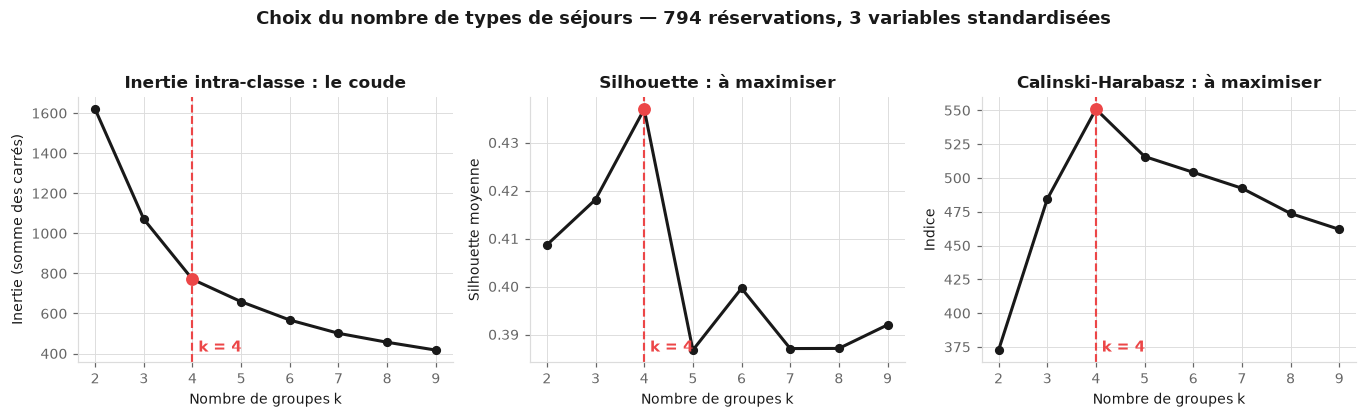

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
k_retenu = 4

# 1. Coude : inertie intra-classe
ax = axes[0]
ax.plot(diagnostic.index, diagnostic["inertie"], color=ENCRE, linewidth=2, marker="o", markersize=5)
ax.set_title("Inertie intra-classe : le coude")
ax.set_xlabel("Nombre de groupes k"); ax.set_ylabel("Inertie (somme des carrés)")

# 2. Silhouette
ax = axes[1]
ax.plot(diagnostic.index, diagnostic["silhouette"], color=ENCRE, linewidth=2, marker="o", markersize=5)
ax.set_title("Silhouette : à maximiser")
ax.set_xlabel("Nombre de groupes k"); ax.set_ylabel("Silhouette moyenne")

# 3. Calinski-Harabasz
ax = axes[2]
ax.plot(diagnostic.index, diagnostic["calinski_harabasz"], color=ENCRE, linewidth=2, marker="o", markersize=5)
ax.set_title("Calinski-Harabasz : à maximiser")
ax.set_xlabel("Nombre de groupes k"); ax.set_ylabel("Indice")

# Le meme repere sur les trois panneaux : le k retenu
for ax, col in zip(axes, ["inertie", "silhouette", "calinski_harabasz"]):
    ax.axvline(k_retenu, color=COULEURS[3], linewidth=1.4, linestyle="--", zorder=1)
    ax.scatter([k_retenu], [diagnostic.loc[k_retenu, col]], color=COULEURS[3], s=55, zorder=3)
    ax.text(k_retenu + 0.12, 0.04, f"k = {k_retenu}", transform=ax.get_xaxis_transform(),
            color=COULEURS[3], fontweight="bold", fontsize=9.5)

fig.suptitle("Choix du nombre de types de séjours — 794 réservations, 3 variables standardisées",
             fontsize=12, fontweight="bold", color=ENCRE, y=1.04)
fig.tight_layout()
plt.show()

**Lecture des quatre critères — ils désignent tous k = 4.**

- **Coude** : l'inertie tombe de 1 620 à 1 071 puis 770 en passant de 2 à 4 groupes (baisses de 549 puis 300).
  Le cinquième groupe ne fait plus gagner que 112. La cassure est nette après 4.
- **Silhouette** : maximum à k = 4 (0,437), contre 0,418 à k = 3 et 0,387 à k = 5.
- **Calinski-Harabasz** : maximum à k = 4 (551).
- **Davies-Bouldin** : minimum à k = 4 (0,881), le plus faible de toute la plage — même si k = 6 le talonne
  (0,889), et c'est le seul des quatre critères qui ne tranche pas nettement.

Aucun des quatre ne désigne 3, le nombre de segments déclarés. C'est le premier signe que la typologie
commerciale actuelle ne décrit pas complètement les données.